Exercitiul 2

Subpunctul a

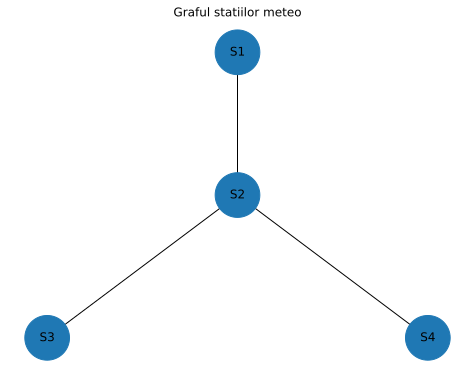

Vecinii fiecarei statii:
S1: ['S2']
S2: ['S1', 'S3', 'S4']
S3: ['S2']
S4: ['S2']

Graful este conex: True
Graful nu contine cicluri: True
Graful este un arbore: True


In [ ]:
import networkx as nx
import matplotlib.pyplot as plt

statii = ["S1", "S2", "S3", "S4"]

muchii = [
    ("S1", "S2"),
    ("S2", "S3"),
    ("S2", "S4")
]

G = nx.Graph()
G.add_nodes_from(statii)
G.add_edges_from(muchii)

pozitii = {
    "S1": (0, 1),
    "S2": (0, 0),
    "S3": (-1, -1),
    "S4": (1, -1)
}

nx.draw(
    G,
    pozitii,
    with_labels=True,
    node_size=2000,
    font_size=12
)

plt.title("Graful statiilor meteo")
plt.show()

print("Vecinii fiecarei statii:")
for statie in statii:
    print(f"{statie}: {list(G.neighbors(statie))}")

print("\nGraful este conex:", nx.is_connected(G))
print("Graful nu contine cicluri:", nx.is_forest(G))
print("Graful este un arbore:", nx.is_tree(G))


Subpunctul b

In [ ]:
import pyagrum as gum

mrf = gum.MarkovRandomField()

stari = ["Soare", "Ploaie", "Nori"]

for statie in ["S1", "S2", "S3", "S4"]:
    mrf.add(gum.LabelizedVariable(statie, statie, stari))

p = [0.5, 0.3, 0.2]

for statie in ["S1", "S2", "S3", "S4"]:
    factor = mrf.addFactor(statie)

    for i in range(3):
        factor[i] = p[i]

Psi = [
    [0.7, 0.2, 0.1],
    [0.2, 0.6, 0.2],
    [0.1, 0.3, 0.6]
]

muchii = [
    ("S1", "S2"),
    ("S2", "S3"),
    ("S2", "S4")
]

for s1, s2 in muchii:
    factor = mrf.addFactor([s1, s2])

    for i in range(3):
        for j in range(3):
            factor[{s1: i, s2: j}] = Psi[i][j]

print(mrf)
print("Modelul Markov a fost construit.")
print("Numar de statii:", len(muchii) + 1)

MRF{nodes: 4, edges: 3, domainSize: 81, dim: 39}
Modelul Markov a fost construit.
Numar de statii: 4


Subpunctul c

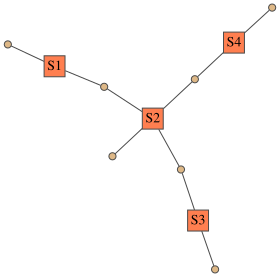

Statiile meteo: ['S1', 'S2', 'S3', 'S4']
Starile posibile: ['Soare', 'Ploaie', 'Nori']
Muchiile grafului: [('S1', 'S2'), ('S2', 'S3'), ('S2', 'S4')]

Probabilitatile initiale:
Soare = 0.5, Ploaie = 0.3, Nori = 0.2

Matricea potentialelor Psi:
[0.7, 0.2, 0.1]
[0.2, 0.6, 0.2]
[0.1, 0.3, 0.6]

Distributia comuna:
P(s1,s2,s3,s4) = (1/Z) * phi1(s1) * phi2(s2) *
phi3(s3) * phi4(s4) * phi12(s1,s2) *
phi23(s2,s3) * phi24(s2,s4)


In [ ]:
import pyagrum.lib.notebook as gnb

gnb.showMRF(mrf)

print("Statiile meteo:", ["S1", "S2", "S3", "S4"])
print("Starile posibile:", ["Soare", "Ploaie", "Nori"])
print("Muchiile grafului:", muchii)

print("\nProbabilitatile initiale:")
print("Soare = 0.5, Ploaie = 0.3, Nori = 0.2")

print("\nMatricea potentialelor Psi:")
for linie in Psi:
    print(linie)

print("\nDistributia comuna:")
print("P(s1,s2,s3,s4) = (1/Z) * phi1(s1) * phi2(s2) *")
print("phi3(s3) * phi4(s4) * phi12(s1,s2) *")
print("phi23(s2,s3) * phi24(s2,s4)")

Subpunctul d

In [ ]:
import pyagrum as gum

ie = gum.ShaferShenoyMRFInference(mrf)

ie.addEvidence("S1", "Soare")

ie.makeInference()

marginal_S3 = ie.posterior("S3")

print("Distributia marginala pentru S3, stiind ca S1 = Soare:")
print(marginal_S3)

probabilitati = [marginal_S3[i] for i in range(3)]
stari = ["Soare", "Ploaie", "Nori"]

index_max = probabilitati.index(max(probabilitati))

print("\nProbabilitati:")
for stare, prob in zip(stari, probabilitati):
    print(f"{stare}: {prob:.4f}")

print("\nStarea MAP marginal pentru S3:", stari[index_max])

Distributia marginala pentru S3, stiind ca S1 = Soare:

  S3                         │
Soare    │Ploaie   │Nori     │
─────────│─────────│─────────│
 0.7557  │ 0.1785  │ 0.0658  │


Probabilitati:
Soare: 0.7557
Ploaie: 0.1785
Nori: 0.0658

Starea MAP marginal pentru S3: Soare


Subpunctul e


In [ ]:
from itertools import product

stari = ["Soare", "Ploaie", "Nori"]

p = [0.5, 0.3, 0.2]

configuratii = list(product(range(3), repeat=4))

rezultate = []

for config in configuratii:

    if config[0] != 0:
        continue

    pondere = 1.0
    for i in range(4):
        pondere *= p[config[i]]

    for s1, s2 in muchii:
        i = int(s1[1]) - 1
        j = int(s2[1]) - 1

        pondere *= Psi[config[i]][config[j]]

    rezultate.append((config, pondere))

rezultate.sort(key=lambda x: x[1], reverse=True)

config_MAP, pondere_max = rezultate[0]

print("Configuratia comuna MAP:")
for i, valoare in enumerate(config_MAP):
    print(f"S{i+1}: {stari[valoare]}")

print("\nPonderea maxima ne-normalizata:", pondere_max)

Configuratia comuna MAP:
S1: Soare
S2: Soare
S3: Soare
S4: Soare

Ponderea maxima ne-normalizata: 0.021437499999999995


In [ ]:

Z_conditionat = sum(pondere for _, pondere in rezultate)

prob_config = [
    (config, pondere / Z_conditionat)
    for config, pondere in rezultate
]

marginale = {}

for pozitie in range(1, 4):
    distributie = [0.0, 0.0, 0.0]

    for config, prob in prob_config:
        distributie[config[pozitie]] += prob

    marginale[f"S{pozitie+1}"] = distributie

print("MAP marginal pentru fiecare statie neobservata:")

config_marginal = [0]

for nume, distributie in marginale.items():
    index_max = distributie.index(max(distributie))
    config_marginal.append(index_max)

    print(f"{nume}:")
    for stare, prob in zip(stari, distributie):
        print(f"  {stare}: {prob:.4f}")
    print(f"  MAP marginal: {stari[index_max]}")

print("\nConfiguratia obtinuta din maximele marginale:")
print([stari[i] for i in config_marginal])

print("\nConfiguratia comuna MAP:")
print([stari[i] for i in config_MAP])

print(
    "\nCele doua configuratii coincid:",
    tuple(config_marginal) == tuple(config_MAP)
)

MAP marginal pentru fiecare statie neobservata:
S2:
  Soare: 0.8962
  Ploaie: 0.0851
  Nori: 0.0187
  MAP marginal: Soare
S3:
  Soare: 0.7596
  Ploaie: 0.1794
  Nori: 0.0610
  MAP marginal: Soare
S4:
  Soare: 0.7596
  Ploaie: 0.1794
  Nori: 0.0610
  MAP marginal: Soare

Configuratia obtinuta din maximele marginale:
['Soare', 'Soare', 'Soare', 'Soare']

Configuratia comuna MAP:
['Soare', 'Soare', 'Soare', 'Soare']

Cele doua configuratii coincid: True


Exercitiul 3

Subpunctul a

Matricea imaginii originale:
[[0 0 0 0 0]
 [0 1 1 1 0]
 [0 1 1 1 0]
 [0 1 1 1 0]
 [0 0 0 0 0]]


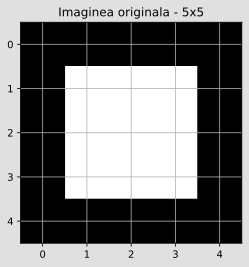

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

imagine_originala = np.zeros((5, 5), dtype=int)

imagine_originala[1:4, 1:4] = 1

print("Matricea imaginii originale:")
print(imagine_originala)

plt.figure(figsize=(4, 4))
plt.imshow(imagine_originala, cmap="gray", vmin=0, vmax=1)
plt.title("Imaginea originala - 5x5")
plt.xticks(range(5))
plt.yticks(range(5))
plt.grid(True)
plt.show()


Subpunctul b

Imaginea originala:
[[0 0 0 0 0]
 [0 1 1 1 0]
 [0 1 1 1 0]
 [0 1 1 1 0]
 [0 0 0 0 0]]

Imaginea cu zgomot:
[[1 0 0 0 0]
 [0 1 1 0 0]
 [0 1 1 1 0]
 [0 0 1 1 0]
 [0 0 0 0 0]]


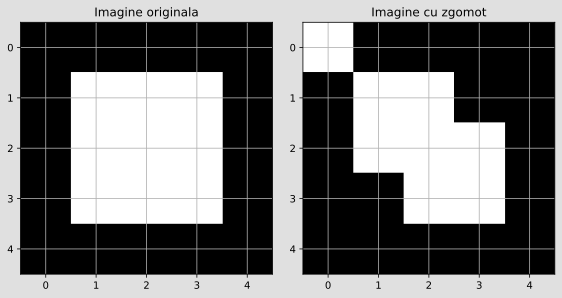

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)

imagine_observata = imagine_originala.copy()
indici = np.random.choice(25, size=3, replace=False)

for index in indici:
    i, j = divmod(index, 5)
    imagine_observata[i, j] = 1 - imagine_observata[i, j]

print("Imaginea originala:")
print(imagine_originala)

print("\nImaginea cu zgomot:")
print(imagine_observata)

fig, axe = plt.subplots(1, 2, figsize=(8, 4))

axe[0].imshow(imagine_originala, cmap="gray", vmin=0, vmax=1)
axe[0].set_title("Imagine originala")
axe[0].set_xticks(range(5))
axe[0].set_yticks(range(5))
axe[0].grid(True)

axe[1].imshow(imagine_observata, cmap="gray", vmin=0, vmax=1)
axe[1].set_title("Imagine cu zgomot")
axe[1].set_xticks(range(5))
axe[1].set_yticks(range(5))
axe[1].grid(True)

plt.tight_layout()
plt.show()

Subpunctul c

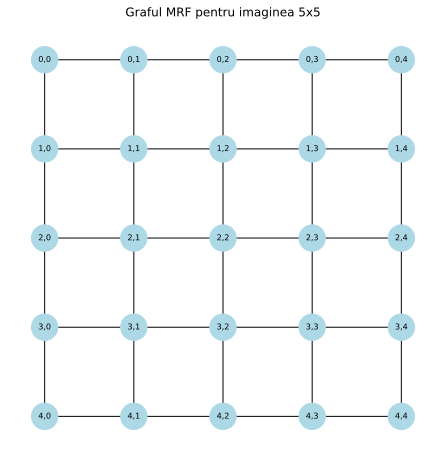

Numar de pixeli: 25
Numar de muchii: 40
Lambda: 1.0
Energia imaginii observate: 14.0


In [ ]:
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np

G = nx.grid_2d_graph(5, 5)

pozitii = {
    (i, j): (j, -i)
    for i in range(5)
    for j in range(5)
}

plt.figure(figsize=(6, 6))
nx.draw(
    G,
    pos=pozitii,
    with_labels=True,
    labels={(i, j): f"{i},{j}" for i, j in G.nodes()},
    node_color="lightblue",
    node_size=700,
    font_size=8
)
plt.title("Graful MRF pentru imaginea 5x5")
plt.show()

lam = 1.0

def energie(imagine, observata, lam):
    termen_date = lam * np.sum((imagine - observata) ** 2)
    termen_vecini = sum(
        (imagine[i, j] - imagine[ni, nj]) ** 2
        for (i, j), (ni, nj) in G.edges()
    )
    return termen_date + termen_vecini

print("Numar de pixeli:", G.number_of_nodes())
print("Numar de muchii:", G.number_of_edges())
print("Lambda:", lam)
print("Energia imaginii observate:", energie(imagine_observata, imagine_observata, lam))

Subpunctul d

Imaginea observata:
[[1 0 0 0 0]
 [0 1 1 0 0]
 [0 1 1 1 0]
 [0 0 1 1 0]
 [0 0 0 0 0]]

Imaginea restaurata:
[[0 0 0 0 0]
 [0 1 1 0 0]
 [0 1 1 1 0]
 [0 0 1 1 0]
 [0 0 0 0 0]]

Energia imaginii observate: 14.0
Energia imaginii restaurate: 13.0


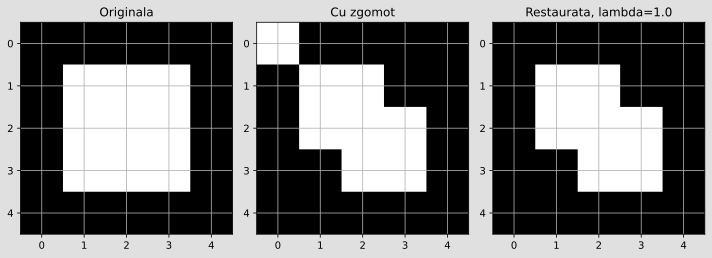

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

def energie(imagine, observata, lam):
    termen_date = lam * np.sum((imagine - observata) ** 2)
    termen_vecini = sum(
        (imagine[i, j] - imagine[ni, nj]) ** 2
        for (i, j), (ni, nj) in G.edges()
    )
    return termen_date + termen_vecini

def icm(observata, lam, max_iter=100):
    imagine = observata.copy().astype(int)

    for _ in range(max_iter):
        modificari = 0

        for i in range(5):
            for j in range(5):
                energii = []

                for valoare in [0, 1]:
                    candidat = imagine.copy()
                    candidat[i, j] = valoare
                    energii.append(energie(candidat, observata, lam))

                valoare_noua = [0, 1][np.argmin(energii)]

                if imagine[i, j] != valoare_noua:
                    imagine[i, j] = valoare_noua
                    modificari += 1

        if modificari == 0:
            break

    return imagine

lam = 1.0
imagine_restaurata = icm(imagine_observata, lam)

print("Imaginea observata:")
print(imagine_observata)

print("\nImaginea restaurata:")
print(imagine_restaurata)

print("\nEnergia imaginii observate:", energie(imagine_observata, imagine_observata, lam))
print("Energia imaginii restaurate:", energie(imagine_restaurata, imagine_observata, lam))

fig, axe = plt.subplots(1, 3, figsize=(10, 4))

axe[0].imshow(imagine_originala, cmap="gray", vmin=0, vmax=1)
axe[0].set_title("Originala")

axe[1].imshow(imagine_observata, cmap="gray", vmin=0, vmax=1)
axe[1].set_title("Cu zgomot")

axe[2].imshow(imagine_restaurata, cmap="gray", vmin=0, vmax=1)
axe[2].set_title(f"Restaurata, lambda={lam}")

for ax in axe:
    ax.set_xticks(range(5))
    ax.set_yticks(range(5))
    ax.grid(True)

plt.tight_layout()
plt.show()

Subpunctul e

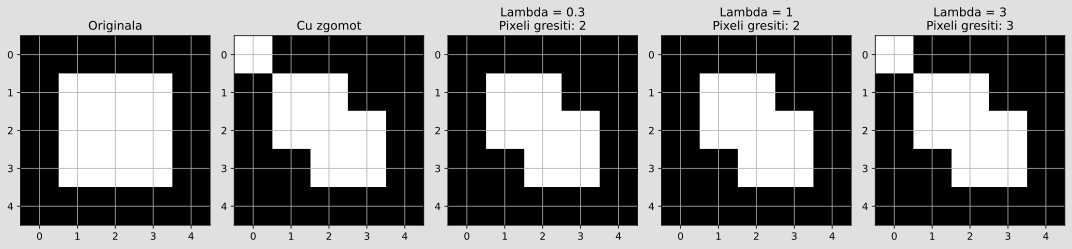

Comparatia rezultatelor:

lambda = 0.3
[[0 0 0 0 0]
 [0 1 1 0 0]
 [0 1 1 1 0]
 [0 0 1 1 0]
 [0 0 0 0 0]]
Numar de pixeli reconstruiti gresit: 2

lambda = 1
[[0 0 0 0 0]
 [0 1 1 0 0]
 [0 1 1 1 0]
 [0 0 1 1 0]
 [0 0 0 0 0]]
Numar de pixeli reconstruiti gresit: 2

lambda = 3
[[1 0 0 0 0]
 [0 1 1 0 0]
 [0 1 1 1 0]
 [0 0 1 1 0]
 [0 0 0 0 0]]
Numar de pixeli reconstruiti gresit: 3


In [ ]:
valori_lambda = [0.3, 1, 3]
rezultate = {}

fig, axe = plt.subplots(1, 5, figsize=(15, 4))

axe[0].imshow(imagine_originala, cmap="gray", vmin=0, vmax=1)
axe[0].set_title("Originala")

axe[1].imshow(imagine_observata, cmap="gray", vmin=0, vmax=1)
axe[1].set_title("Cu zgomot")

for k, lam in enumerate(valori_lambda):
    restaurata = icm(imagine_observata, lam)
    erori = np.sum(restaurata != imagine_originala)
    rezultate[lam] = (restaurata, erori)

    axe[k + 2].imshow(restaurata, cmap="gray", vmin=0, vmax=1)
    axe[k + 2].set_title(f"Lambda = {lam}\nPixeli gresiti: {erori}")

for ax in axe:
    ax.set_xticks(range(5))
    ax.set_yticks(range(5))
    ax.grid(True)

plt.tight_layout()
plt.show()

print("Comparatia rezultatelor:")
for lam, (restaurata, erori) in rezultate.items():
    print(f"\nlambda = {lam}")
    print(restaurata)
    print("Numar de pixeli reconstruiti gresit:", erori)